In [1]:
# Configuración general
import heapq
from collections import deque
import matplotlib.pyplot as plt

## Etapa 1: Problema

**Pregunta:** ¿cuál es la ruta de decisiones más barata para llevar el proyecto desde la exploración (poco capital, riesgo alto) hasta una operación rentable?

- **Estado inicial:** `S0`
- **Estado meta:** `META`
- **Criterio:** minimizar el costo total acumulado, en millones de USD.

In [2]:
# ETAPA 1: PROBLEMA
ESTADO_INICIAL = "S0"
ESTADO_META = "META"

print("Problema : decidir el nivel de inversión en la minería de asteroides")
print("Inicio   :", ESTADO_INICIAL, "(exploración, poco capital, riesgo alto)")
print("Meta     :", ESTADO_META, "(operación rentable, capital alto, riesgo controlado)")
print("Criterio : minimizar el costo total (millones de USD)")

Problema : decidir el nivel de inversión en la minería de asteroides
Inicio   : S0 (exploración, poco capital, riesgo alto)
Meta     : META (operación rentable, capital alto, riesgo controlado)
Criterio : minimizar el costo total (millones de USD)


## Etapa 2: Espacio de Estados

Cada estado es una tupla `(fase tecnológica, capital, riesgo)`. Las acciones (`A1` a `A6`) llevan de un estado a otro con un costo. La heurística `h` estima el costo que falta hasta la meta y la usará A*.

In [3]:
# ETAPA 2: ESPACIO DE ESTADOS
# Estado S = (fase tecnológica, capital, riesgo)
estados = {
    "S0":    ("exploración",         "poco capital",  "riesgo alto"),    # inicial
    "S1":    ("recursos detectados", "capital medio", "riesgo alto"),
    "S2":    ("robótica madura",     "capital medio", "riesgo medio"),
    "S3":    ("misión demo OK",      "capital alto",  "riesgo medio"),
    "S4":    ("regulación",          "capital alto",  "riesgo bajo"),
    "META":  ("operación rentable",  "capital alto",  "riesgo controlado"),
    "PAUSA": ("detenido",            "-",             "-"),
}

# Acciones: A1 explorar, A2 robótica, A3 misión demo, A4 regulación, A5 escalar, A6 pausar
ACCIONES = {"A1": "Explorar", "A2": "Desarrollar robótica", "A3": "Misión demostrativa",
            "A4": "Cumplir regulación", "A5": "Escalar la operación", "A6": "Pausar"}

# estado: [(acción, estado nuevo, costo en millones USD)]
grafo = {
    "S0": [("A1", "S1", 10),   ("A6", "PAUSA", 0)],
    "S1": [("A2", "S2", 25),   ("A6", "PAUSA", 0)],
    "S2": [("A3", "S3", 40),   ("A6", "PAUSA", 0)],
    "S3": [("A4", "S4", 15),   ("A6", "PAUSA", 0)],
    "S4": [("A5", "META", 60), ("A6", "PAUSA", 0)],
    "META": [], "PAUSA": [],
}

# Costo estimado que falta hasta la meta (heurística para A*)
h = {"S0": 140, "S1": 130, "S2": 100, "S3": 70, "S4": 55, "META": 0, "PAUSA": 999}

print(f"{'Estado':<6} | {'Fase':<20} | {'Capital':<13} | Riesgo")
print("-" * 62)
for e, (fase, cap, riesgo) in estados.items():
    print(f"{e:<6} | {fase:<20} | {cap:<13} | {riesgo}")

print()
print("Transiciones (estado --acción/costo--> nuevo estado):")
for e, salidas in grafo.items():
    for a, nuevo, c in salidas:
        print(f"  {e:<4} --{a} ({ACCIONES[a]}, {c} M USD)--> {nuevo}")

total = sum(len(s) for s in grafo.values())
print(f"\nTotal: {len(estados)} estados y {total} transiciones")

Estado | Fase                 | Capital       | Riesgo
--------------------------------------------------------------
S0     | exploración          | poco capital  | riesgo alto
S1     | recursos detectados  | capital medio | riesgo alto
S2     | robótica madura      | capital medio | riesgo medio
S3     | misión demo OK       | capital alto  | riesgo medio
S4     | regulación           | capital alto  | riesgo bajo
META   | operación rentable   | capital alto  | riesgo controlado
PAUSA  | detenido             | -             | -

Transiciones (estado --acción/costo--> nuevo estado):
  S0   --A1 (Explorar, 10 M USD)--> S1
  S0   --A6 (Pausar, 0 M USD)--> PAUSA
  S1   --A2 (Desarrollar robótica, 25 M USD)--> S2
  S1   --A6 (Pausar, 0 M USD)--> PAUSA
  S2   --A3 (Misión demostrativa, 40 M USD)--> S3
  S2   --A6 (Pausar, 0 M USD)--> PAUSA
  S3   --A4 (Cumplir regulación, 15 M USD)--> S4
  S3   --A6 (Pausar, 0 M USD)--> PAUSA
  S4   --A5 (Escalar la operación, 60 M USD)--> META
  S4   --A6

In [4]:
# Verificación de la heurística: ¿h(n) <= costo real que falta h*(n)?
def costo_real_restante(e):
    if e == ESTADO_META:
        return 0
    opciones = [c + costo_real_restante(n) for _, n, c in grafo[e]]
    return min(opciones) if opciones else float("inf")

print(f"{'Estado':<6} | {'h(n)':>5} | {'h*(n)':>6} | ¿h <= h*?")
for e in ["S0", "S1", "S2", "S3", "S4", "META"]:
    real = costo_real_restante(e)
    print(f"{e:<6} | {h[e]:>5} | {real:>6} | {'sí' if h[e] <= real else 'NO'}")

print()
print("Consistencia: h(n) <= costo(n, n') + h(n') para cada acción de avance")
for e, salidas in grafo.items():
    for a, nuevo, c in salidas:
        if nuevo not in ("PAUSA",) and e != "META":
            ok = h[e] <= c + h[nuevo]
            print(f"  {e} -> {nuevo}: {h[e]} <= {c} + {h[nuevo]} = {c + h[nuevo]}  {'ok' if ok else 'NO cumple'}")

Estado |  h(n) |  h*(n) | ¿h <= h*?
S0     |   140 |    150 | sí
S1     |   130 |    140 | sí
S2     |   100 |    115 | sí
S3     |    70 |     75 | sí
S4     |    55 |     60 | sí
META   |     0 |      0 | sí

Consistencia: h(n) <= costo(n, n') + h(n') para cada acción de avance
  S0 -> S1: 140 <= 10 + 130 = 140  ok
  S1 -> S2: 130 <= 25 + 100 = 125  NO cumple
  S2 -> S3: 100 <= 40 + 70 = 110  ok
  S3 -> S4: 70 <= 15 + 55 = 70  ok
  S4 -> META: 55 <= 60 + 0 = 60  ok


La heurística es **admisible**: nunca sobreestima el costo real que falta, así que A* no se pasa de largo la ruta óptima.

Hay un detalle fino: entre `S1` y `S2` **no es consistente** (130 > 25 + 100). Para este problema no es grave, porque nuestra implementación de A* no descarta estados ya visitados, y en ese caso la admisibilidad basta para garantizar que la primera vez que se llega a la meta es con el menor costo.

## Etapa 3: Exploración

Antes de buscar la solución, miramos **cómo se recorre el espacio**: en qué orden se van expandiendo los estados con cada estrategia.

- **BFS** explora por niveles, sin mirar costos.
- **A\*** expande primero el estado con menor `f(n) = g(n) + h(n)`, donde `g` es lo gastado hasta ahí y `h` lo estimado que falta.

In [5]:
# ETAPA 3: EXPLORACIÓN (traza paso a paso)
def explorar_bfs():
    cola = deque([("S0", 0)])
    vistos = {"S0"}
    orden = []
    while cola:
        e, g = cola.popleft()
        orden.append((e, g))
        if e == ESTADO_META:
            break
        for a, nuevo, c in grafo[e]:
            if nuevo not in vistos:
                vistos.add(nuevo)
                cola.append((nuevo, g + c))
    return orden

def explorar_a_estrella():
    cola = [(h["S0"], 0, "S0")]          # (f, g, estado)
    orden = []
    while cola:
        f, g, e = heapq.heappop(cola)
        orden.append((e, g, h[e], f))
        if e == ESTADO_META:
            break
        for a, nuevo, c in grafo[e]:
            heapq.heappush(cola, (g + c + h[nuevo], g + c, nuevo))
    return orden

print("BFS: orden en que se expanden los estados")
for i, (e, g) in enumerate(explorar_bfs(), start=1):
    print(f"  {i}. {e:<5} (gastado hasta aquí: {g} M USD)")

print("\nA*: orden de expansión con f = g + h")
for i, (e, g, he, f) in enumerate(explorar_a_estrella(), start=1):
    print(f"  {i}. {e:<5} g={g:<3} h={he:<3} f={f}")

BFS: orden en que se expanden los estados
  1. S0    (gastado hasta aquí: 0 M USD)
  2. S1    (gastado hasta aquí: 10 M USD)
  3. PAUSA (gastado hasta aquí: 0 M USD)
  4. S2    (gastado hasta aquí: 35 M USD)
  5. S3    (gastado hasta aquí: 75 M USD)
  6. S4    (gastado hasta aquí: 90 M USD)
  7. META  (gastado hasta aquí: 150 M USD)

A*: orden de expansión con f = g + h
  1. S0    g=0   h=140 f=140
  2. S1    g=10  h=130 f=140
  3. S2    g=35  h=100 f=135
  4. S3    g=75  h=70  f=145
  5. S4    g=90  h=55  f=145
  6. META  g=150 h=0   f=150


**Qué se observa:**

- BFS pierde un paso expandiendo `PAUSA`, porque no sabe que ese camino nunca llega a la meta.
- A* nunca expande `PAUSA`: su `f` es enorme (`h = 999`), así que siempre hay otro estado más prometedor en la cola.

## Etapa 4: Búsqueda

Ahora ejecutamos las dos estrategias como algoritmos completos. Cada una devuelve la **ruta** (lista de acciones), el **costo total** y los **nodos expandidos**.

In [6]:
# ETAPA 4: BÚSQUEDA
def bfs():
    cola = deque([("S0", [], 0)])
    vistos = {"S0"}
    n = 0
    while cola:
        e, ruta, costo = cola.popleft()
        n += 1
        if e == ESTADO_META:
            return ruta, costo, n
        for a, nuevo, c in grafo[e]:
            if nuevo not in vistos:
                vistos.add(nuevo)
                cola.append((nuevo, ruta + [a], costo + c))

def a_estrella():
    cola = [(h["S0"], 0, "S0", [])]      # (f, g, estado, ruta)
    n = 0
    while cola:
        f, g, e, ruta = heapq.heappop(cola)
        n += 1
        if e == ESTADO_META:
            return ruta, g, n
        for a, nuevo, c in grafo[e]:
            heapq.heappush(cola, (g + c + h[nuevo], g + c, nuevo, ruta + [a]))

resultados = {}
for nombre, algoritmo in [("BFS", bfs), ("A*", a_estrella)]:
    ruta, costo, nodos = algoritmo()
    resultados[nombre] = (ruta, costo, nodos)
    print(nombre, "| ruta:", " -> ".join(ruta), "| costo:", costo, "M USD | nodos expandidos:", nodos)

# Coherencia con la traza de la Etapa 3
assert resultados["BFS"][2] == len(explorar_bfs())
assert resultados["A*"][2] == len(explorar_a_estrella())

BFS | ruta: A1 -> A2 -> A3 -> A4 -> A5 | costo: 150 M USD | nodos expandidos: 7
A* | ruta: A1 -> A2 -> A3 -> A4 -> A5 | costo: 150 M USD | nodos expandidos: 6


Las dos estrategias encuentran la misma ruta y el mismo costo. En este espacio **hay un único camino a la meta**, así que no podía ser de otra forma. La diferencia está en el esfuerzo: A* llega con un nodo menos expandido.

En un espacio mayor (más fases, rutas alternativas o varios proyectos a la vez) esa diferencia crece, porque la heurística evita explorar ramas poco prometedoras.

## Etapa 5: Resultado

Traducimos la ruta encontrada a algo que se pueda leer como una recomendación de inversión.

In [7]:
# ETAPA 5: RESULTADO
ruta, costo_total, _ = resultados["A*"]

estado = "S0"
acumulado = 0
trayecto = [("S0", 0)]          # (estado, capital acumulado)

print("Ruta recomendada (menor costo):\n")
for a in ruta:
    for ac, nuevo, c in grafo[estado]:
        if ac == a:
            acumulado += c
            print(f"  {estado:<3} --{a} {ACCIONES[a]:<22} (+{c:>2} M USD)--> {nuevo:<5} | acumulado: {acumulado:>3} M USD")
            estado = nuevo
            trayecto.append((estado, acumulado))
            break

print(f"\nEstado final: {estado} | Costo total: {costo_total} M USD | Acciones: {len(ruta)}")
assert estado == ESTADO_META and acumulado == costo_total

Ruta recomendada (menor costo):

  S0  --A1 Explorar               (+10 M USD)--> S1    | acumulado:  10 M USD
  S1  --A2 Desarrollar robótica   (+25 M USD)--> S2    | acumulado:  35 M USD
  S2  --A3 Misión demostrativa    (+40 M USD)--> S3    | acumulado:  75 M USD
  S3  --A4 Cumplir regulación     (+15 M USD)--> S4    | acumulado:  90 M USD
  S4  --A5 Escalar la operación   (+60 M USD)--> META  | acumulado: 150 M USD

Estado final: META | Costo total: 150 M USD | Acciones: 5


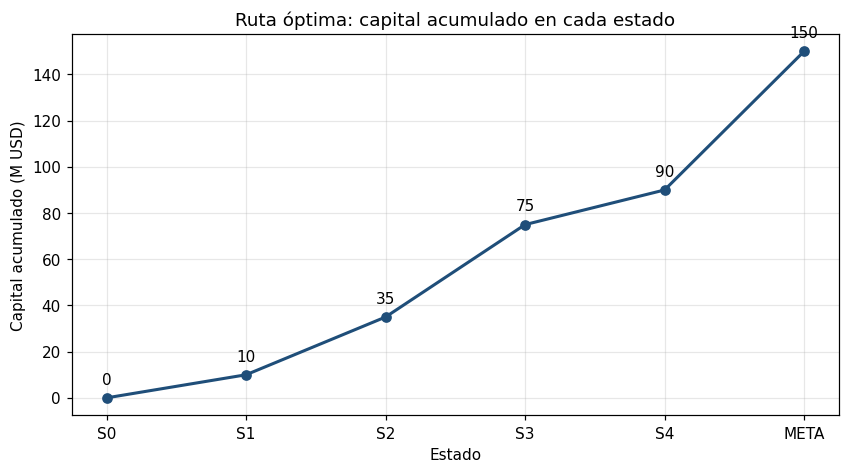

In [8]:
# Gráfica del resultado: capital acumulado a lo largo de la ruta óptima
nombres = [e for e, _ in trayecto]
capital_acum = [c for _, c in trayecto]

plt.figure(figsize=(9, 4.5))
plt.plot(nombres, capital_acum, "o-", color="#1f4e79", lw=2)
for e, c in trayecto:
    plt.annotate(f"{c}", (e, c), textcoords="offset points", xytext=(0, 9), ha="center")
plt.xlabel("Estado")
plt.ylabel("Capital acumulado (M USD)")
plt.title("Ruta óptima: capital acumulado en cada estado")
plt.grid(alpha=0.3)
plt.show()

### Conclusiones del pipeline

- **Resultado:** la ruta de menor costo es `A1 -> A2 -> A3 -> A4 -> A5` (`S0 -> S1 -> S2 -> S3 -> S4 -> META`), con un costo total de **150 M USD**.
- **Pausar** cuesta 0, pero deja el proyecto detenido: es la salida cuando el riesgo o el capital no se justifican, no un camino a la meta.
- **BFS vs A\*:** ambos dan la misma solución; A* expande menos nodos gracias a la heurística.
- **Límites:** los costos y la heurística son valores referenciales del caso. Un proyecto real tendría incertidumbre en los costos y varias rutas alternativas.

Los capitales acumulados de la gráfica (0, 10, 35, 75, 90, 150) son los que usamos como datos de entrada del modelo de predicción en `02_pipeline_prediccion.ipynb` (Rubro 4).